In [1]:
#Shishir Khanal
#Sept 10, 2026
#Lunar lander using Actor_Critic algorithm
#Actions: Do nothing, Fire Left Engine, Fire main Engine, Fire Right Engine
#Positive Score - Soft landing

In [2]:
import gym
import numpy as np
import tensorflow as tf
import tensorflow.keras as keras
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
import tensorflow_probability as tfp
import matplotlib.pyplot as plt

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
2026-09-10 11:04:12.548468: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
class ActorCriticNetwork(keras.Model):
    def __init__(self, n_actions, fc1_dims=1024, fc2_dims=512):
        super(ActorCriticNetwork, self).__init__()
        self.fc1 = Dense(fc1_dims, activation='relu', name='fc1')
        self.fc2 = Dense(fc2_dims, activation='relu', name='fc2')
        self.pi = Dense(n_actions, activation='softmax', name='dense_2')
        self.v = Dense(1, activation=None, name='dense_3')
    
    def call(self, state):
        x = self.fc1(state)
        x = self.fc2(x)
        pi = self.pi(x)
        v = self.v(x)
        return v, pi

In [4]:
class Agent:
    def __init__(self, alpha=0.0003, gamma=0.99, n_actions=4, fc1_dims=256, fc2_dims=256, chkpt_dir ='models/'):
        self.gamma = gamma
        self.action = None #Last action we took
        self.chkpt_dir = chkpt_dir
        self.actor_critic = ActorCriticNetwork(n_actions=n_actions, fc1_dims=fc1_dims, fc2_dims=fc2_dims)
        self.actor_critic.compile(optimizer=Adam(learning_rate=alpha))

    def save_models(self):
        self.actor_critic.save_weights(self.chkpt_dir + 'actor_critic.weights.h5')
        print('Model saved successfully...')

    def load_models(self):
        dummy_state = tf.zeros((1, 4), dtype=tf.float32)
        self.actor_critic(dummy_state, training=False)
        self.actor_critic.load_weights(self.chkpt_dir+'actor_critic.weights.h5')
        print('Model loaded successfully...')

    def choose_action(self, observation):
        #Operation takes place outside of gradient tape
        #Recalculate pd in learn function
        state = tf.convert_to_tensor([observation], dtype=tf.float32)
        _, probabilities = self.actor_critic(state) #Only care about actual PD
        action_probs = tfp.distributions.Categorical(probs=probabilities)
        action = action_probs.sample()
        self.action = action
        return action.numpy()[0]

    def learn(self, state, reward, state_, done):
        #No need to zero out gradients but conver to tensors
        state = tf.convert_to_tensor([state], dtype=tf.float32)
        state_ = tf.convert_to_tensor([state_], dtype=tf.float32)
        reward = tf.convert_to_tensor(reward, dtype=tf.float32)
        

        with tf.GradientTape() as tape:
            state_value, probs = self.actor_critic(state) #Cant squeeze a tuple so squeeze has to be separate
            state_value_, _ = self.actor_critic(state_)
            state_value = tf.squeeze(state_value) #Squeeze to get rid of batch dim
            state_value_ = tf.squeeze(state_value_)

            action_probs = tfp.distributions.Categorical(probs=probs)
            log_prob = action_probs.log_prob(self.action)
            delta = reward + self.gamma * state_value_ * (1 - int(done)) - state_value
            actor_loss = -log_prob * delta
            critic_loss = delta **2
            total_loss = actor_loss + critic_loss
            
        params = self.actor_critic.trainable_variables
        grads = tape.gradient(total_loss, params)
        self.actor_critic.optimizer.apply_gradients(zip(grads, params))

In [5]:
def manage_memory():
    gpus = tf.config.list_physical_devices('GPU')
    if gpus:
        try:
            for gpu in gpus:
                tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError as e:
            print(e)

In [6]:
def plot_learning_curve(scores, x, figure_file):
    running_avg = np.zeros(len(scores))
    for i in range(len(running_avg)):
        running_avg[i] = np.mean(scores[max(0, i-100):(i+1)])
    plt.plot(x, running_avg)
    plt.title('Running average of previous 100 scores')
    plt.show()
    plt.savefig(figure_file)

In [7]:
if __name__ == '__main__':
    #manage_memory()
    #env = gym.make('CartPole-v1', render_mode="human")
    env = gym.make('CartPole-v1')
    n_games = 2000
    agent = Agent(gamma=0.99, alpha= 1e-5, n_actions=env.action_space.n)
    load_checkpoint = False
    best_score = env.reward_range[0]
    if load_checkpoint:
        n_games = 1
        agent.load_models()
        
    scores = []
    for i in range(n_games):
        done = False
        observation, info = env.reset()
        score = 0
        while not done:
            action = agent.choose_action(observation)
            observation_, reward, truncated, terminated, info = env.step(action)
            done = truncated or terminated
            score += reward
            
            #env.render()
            if not load_checkpoint:
                agent.learn(observation, reward, observation_, done)
            observation = observation_ #current state = new state
        scores.append(score)

        avg_score = np.mean(scores[-100:])
        if avg_score > best_score:
            if not load_checkpoint:
                agent.save_models()
            best_score = avg_score
        print('episode {} score {:.1f} average score {:.1f}'.format(i, score, avg_score))
    figure_file = 'plots/cartpole.png'
    x = [i+1 for i in range(n_games)]


2026-09-10 11:04:15.400876: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_COMPAT_NOT_SUPPORTED_ON_DEVICE: forward compatibility was attempted on non supported HW
2026-09-10 11:04:15.400920: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:171] verbose logging is disabled. Rerun with verbose logging (usually --v=1 or --vmodule=cuda_diagnostics=1) to get more diagnostic output from this module
2026-09-10 11:04:15.400925: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:176] retrieving CUDA diagnostic information for host: shishir
2026-09-10 11:04:15.400956: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:183] hostname: shishir
2026-09-10 11:04:15.401150: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:190] libcuda reported version is: 580.178.4
2026-09-10 11:04:15.401185: I external/local_xla/xla/stream_executor/cuda/cud

Model saved successfully...
episode 0 score 11.0 average score 11.0
Model saved successfully...
episode 1 score 17.0 average score 14.0
episode 2 score 9.0 average score 12.3
episode 3 score 9.0 average score 11.5
episode 4 score 18.0 average score 12.8
episode 5 score 20.0 average score 14.0
Model saved successfully...
episode 6 score 18.0 average score 14.6
Model saved successfully...
episode 7 score 23.0 average score 15.6
Model saved successfully...
episode 8 score 42.0 average score 18.6
episode 9 score 12.0 average score 17.9
episode 10 score 14.0 average score 17.5
episode 11 score 14.0 average score 17.2
episode 12 score 29.0 average score 18.2
episode 13 score 23.0 average score 18.5
Model saved successfully...
episode 14 score 21.0 average score 18.7
episode 15 score 12.0 average score 18.2
episode 16 score 19.0 average score 18.3
episode 17 score 14.0 average score 18.1
episode 18 score 15.0 average score 17.9
episode 19 score 10.0 average score 17.5
episode 20 score 15.0 av

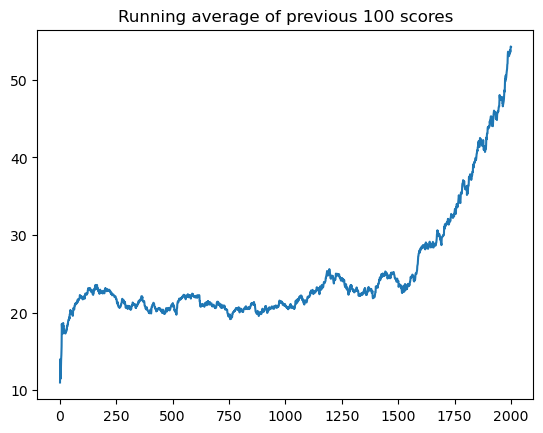

<Figure size 640x480 with 0 Axes>

In [8]:
plot_learning_curve(scores, x, figure_file)